In [1]:
#!pip install scikit-learn==1.3.2
import numpy as np
import pandas as pd
import math, time
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_validate
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import KFold, RepeatedKFold, StratifiedKFold
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import make_scorer
from timeit import default_timer as timer

In [2]:
!pwd

/global/cfs/cdirs/m3195/wallaceg/TORIC_surrogate


In [6]:
##########################
# LOAD using joblib #
##########################
import joblib

# load
model2 = joblib.load("/global/cfs/projectdirs/m3195/wallaceg/TORIC_surrogate/TORIC_MLP_PwHe3.lzma") # load trained random forest regressor model
scaler2 = joblib.load("/global/cfs/projectdirs/m3195/wallaceg/TORIC_surrogate/TORIC_MLP_scaler.lzma") # load scaler for inputs
pca2 = joblib.load("/global/cfs/projectdirs/m3195/wallaceg/TORIC_surrogate/TORIC_MLP_PCA_PwHe3.lzma") # load pca model

[[ 1.12483026e-02  4.91895062e-01  1.63952858e+00 -8.78707509e-01
  -5.80015001e-01 -1.05504468e+00  8.45860698e-04 -1.72462018e+00
   4.14148854e+00  2.44676527e-01]
 [ 1.12483026e-02  4.91895062e-01  1.63952858e+00 -8.78707509e-01
  -5.80015001e-01 -1.05504468e+00  8.45860698e-04 -1.72462018e+00
   4.14148854e+00 -1.73742229e+00]]


/global/common/software/nersc/pe/conda-envs/24.1.0/python-3.11/nersc-python/lib/python3.11/site-packages/sklearn/base.py:465: UserWarning: X does not have valid feature names, but StandardScaler was fitted with feature names
  warnings.warn(


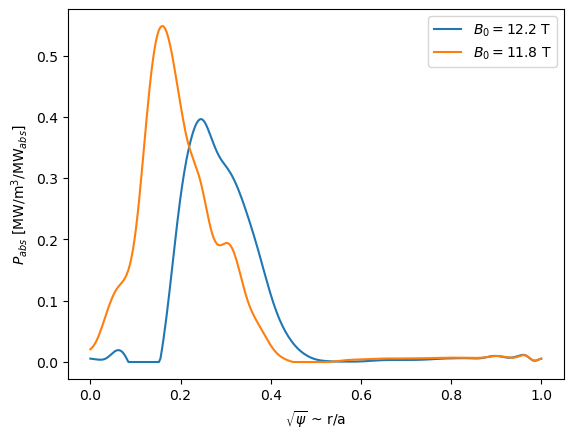

In [8]:
features = ['freq','T_avol','n_avol','min_conc','gap_inner','gap_outer','z0','nu_T','nu_n','B0']
x = [[120.0e6,6,5,2.0,0.01,0.01,0.0,2,2,12.2],[120.0e6,6,5,2.0,0.01,0.01,0.0,2,2,11.8]] # values for each input feature
# input features in x has two rows so we can compare predictions with different inputs
x_scal = scaler2.transform(x) # scale input feature values based on range used in the model
print(x_scal)
rya = np.linspace(0,1,297) # radial grid for surrogate model, sqrt(psi) ~ r/a
y = pca2.inverse_transform(model2.predict(x_scal)) # run surrogate model for feature inputs in x
y = y * (y > 0) # eliminate non-physical negative values for power deposition
#print(y)
#print(rya)
plt.plot(rya,y[0,:])
plt.plot(rya,y[1,:])
plt.xlabel('$\sqrt{\psi}$ ~ r/a')
plt.ylabel('$P_{abs}$ [MW/m$^3$/MW$_{abs}$]')
plt.legend(['$B_0=12.2$ T','$B_0=11.8$ T'])